# EN.605.631 — Conditional Probability & Independence with R (Chapter 3)

**Submission format:** Jupyter Notebook (**R kernel**)  
**Estimated time:** ~5 hours  
**Total points:** 100

## Instructions

- Work directly in this notebook. For each problem, start with a short **plan/derivation** in Markdown, then place your **R code** in the empty code cell(s) below the prompt, followed by a brief interpretation.  
- At the very top, include environment information and set a fixed seed.  
- Your notebook should run cleanly top-to-bottom with **Restart & Run All** in under ~2 minutes.
- **Filename on submission:** `lastname_firstname_ch3_conditional_independence.ipynb`

## Required setup (fill in this cell with R code)
- Show `R.version.string` and `sessionInfo()`  
- Set a seed: `set.seed(631)`  
- List any packages you load (base R is sufficient; `ggplot2` optional)

In [1]:
R.version.string
sessionInfo()

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

In [2]:
set.seed(631)

---
## Problem 1 — Conditioning by enumeration & simulation (20 pts)

Two fair dice are rolled.

1. **Analytic.** Compute  
   (a) \(P(\text{sum}=7\mid \text{at least one die is }4)\)  
   (b) \(P(\text{first die is }3\mid \text{sum is even})\)  
   Provide clear sample-space reasoning.

2. **Computation.** (i) Enumerate all 36 outcomes and verify (a)–(b). (ii) Simulate \(10^5\) rolls to approximate the conditionals with 95% CIs.  
Also verify the multiplication rule \(P(AB)=P(A\mid B)P(B)\) for any pair you use.

## 1)

$S=\{(d_1,d_2) \text{ where } d_1, d_2 \in \{1,2,3,4,5,6\}\}$

### a) $P(d_1+d_2=7\mid\text{at least one die is }4)$

Let $A:d_1+d_2=7$ and $B:d_1=4 \text{ or }d_2=4$.

$P(A\mid B)=\frac{|A\cap B|}{|B|}$

$A=\{(1,6),(2,5),(3,4),(4,3),(5,2),(6,1)\}$

$B=\{(4,1),(4,2),(4,3),(4,4),(4,5),(4,6),(1,4),(2,4),(3,4),(5,4),(6,4)\}$ and $|B|=11$

$A\cap B={(4,3),(3,4)}$ and $|A\cap B|=2$

$P(A\mid B)=\frac{|A\cap B|}{|B|}=\frac{2}{11}=0.1818$

### b) $P(d_1=3\mid (d_1+d_2) \text{ \% } 2 = 0)$

Let $A=\{d_1=3\}$ and $B=\{(d_1+d_2) \text{ \% } 2 = 0\}$

$P(A\mid B)=\frac{|A\cap B|}{|B|}$

$A=\{(3,1),(3,2),(3,3),(3,4),(3,5),(3,6)\}$

$B=\{(1,1),(1,3),(1,5),(2,2),(2,4),(2,6),(3,1),(3,3),(3,5),(4,2),(4,4),(4,6),(5,1),(5,3),(5,5),(6,2),(6,4),(6,6)\}$ and $|B|=18$

$A\cap B={(3,1),(3,3),(3,5)}$ and $|A\cap B|=3$

$P(A\mid B)=\frac{|A\cap B|}{|B|}=\frac{3}{18}=0.1667$.

## 2)

In [3]:
S <- expand.grid(d1 = 1:6, d2 = 1:6)
head(S, 8)
nrow(S)

,d1,d2
,<int>,<int>
1,1,1
2,2,1
3,3,1
4,4,1
5,5,1
6,6,1
7,1,2
8,2,2


[1] 36

In [4]:
A <- with(S, d1 + d2 == 7)
B <- with(S, d1 == 4 | d2 == 4)
A
B
sum(A & B)
sum(B)
PAgivenB <- sum(A & B) / sum(B)
PAgivenB

[1] FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE FALSE FALSE  TRUE FALSE
[13] FALSE FALSE FALSE  TRUE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE FALSE
[25] FALSE  TRUE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE

[1] FALSE FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE
[13] FALSE FALSE FALSE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
[25] FALSE FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE

[1] 2

[1] 11

[1] 0.1818182

In [5]:
A <- with(S, d1 == 3)
B <- with(S, (d1 + d2) %% 2 == 0)
A
B
sum(A & B)
sum(B)
PAgivenB <- sum(A & B) / sum(B)
PAgivenB

[1] FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE FALSE
[13] FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE FALSE
[25] FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE FALSE

[1]  TRUE FALSE  TRUE FALSE  TRUE FALSE FALSE  TRUE FALSE  TRUE FALSE  TRUE
[13]  TRUE FALSE  TRUE FALSE  TRUE FALSE FALSE  TRUE FALSE  TRUE FALSE  TRUE
[25]  TRUE FALSE  TRUE FALSE  TRUE FALSE FALSE  TRUE FALSE  TRUE FALSE  TRUE

[1] 3

[1] 18

[1] 0.1666667

Multiplication rule says $P(A\cap B)=P(A\mid B)P(B)$

For $A:{d_1+d_2=7}$ and $B:{\text{at least one die is }4}$,

$P(A\cap B)=\frac{2}{36}$ and $P(B)=\frac{11}{36}$

$P(A\mid B)P(B)=\frac{2}{11}\frac{11}{36}=\frac{2}{36}=\frac{1}{18}=P(A\cap B)$

In [6]:
A <- with(S, d1 + d2 == 7)
B <- with(S, d1 == 4 | d2 == 4)
PAgivenB <- sum(A & B) / sum(B)

lhs <- mean(A & B)
rhs <- PAgivenB * mean(B)
lhs
rhs

[1] 0.05555556

[1] 0.05555556

For $A:{d_1=3}$ and $B:(d_1+d_2) \text{ \% } 2 = 0$

$P(A\cap B)=\frac{3}{36}=\frac{1}{12}$

$P(A\mid B)P(B)=\frac{1}{6}\frac{18}{36}=\frac{1}{12}$

In [7]:
A <- with(S, d1 == 3)
B <- with(S, (d1 + d2) %% 2 == 0)
PAgivenB <- sum(A & B) / sum(B)

lhs <- mean(A & B)
rhs <- PAgivenB * mean(B)
lhs
rhs

[1] 0.08333333

[1] 0.08333333

#### Monte Carlo Simulation

In [8]:
n <- 100000
d1 <- sample(1:6, n, replace = TRUE)
d2 <- sample(1:6, n, replace = TRUE)

A_sim <- (d1 + d2 == 7)
B_sim <- (d1 == 4 | d2 == 4)

p_a_sim <- sum(A_sim & B_sim) / sum(B_sim)
p_a_sim

[1] 0.1795665

In [9]:
n_B <- sum(B_sim)
x_AB <- sum(A_sim & B_sim)
ci_a <- binom.test(x = x_AB, n = n_B, conf.level = 0.95)$conf.int
ci_a

[1] 0.1752888 0.1839048
attr(,"conf.level")
[1] 0.95

In [10]:
n <- 100000
d1 <- sample(1:6, n, replace = TRUE)
d2 <- sample(1:6, n, replace = TRUE)

A_sim <- (d1 == 3)
B_sim <- ((d1 + d2) %% 2 == 0)

p_a_sim <- sum(A_sim & B_sim) / sum(B_sim)
p_a_sim

[1] 0.1641108

In [11]:
n_B <- sum(B_sim)
x_AB <- sum(A_sim & B_sim)
ci_a <- binom.test(x = x_AB, n = n_B, conf.level = 0.95)$conf.int
ci_a

[1] 0.1608744 0.1673862
attr(,"conf.level")
[1] 0.95

---
## Problem 2 — Law of total probability & Bayes in diagnostics (20 pts)

A screening test has sensitivity 0.92 and specificity 0.95; disease prevalence is \(\pi\in[0.001,0.3]\).

1. Derive **PPV** = \(P(D\mid +)\) and **NPV** = \(P(D^c\mid -)\) as functions of \(\pi\). Implement `ppv(pi)` and `npv(pi)` in R.  
2. Plot PPV and NPV versus \(\pi\) on the same graph; annotate the \(\pi\) where PPV crosses 0.5.  
3. Monte Carlo validation for \(\pi\in\{0.01,0.05,0.20\}\) with \(N=10^6\) (vectorized): report empirical PPV/NPV and Monte Carlo SEs; comment briefly.

## 1)

Let $D={\text{person has the disease}}$ and $D^c={\text{person does not have the disease}}$

$P(D)=\pi$ and  $P(D^c)=1-\pi$

$P(+\mid D)=0.92$ and $P(-\mid D^c)=0.95$

The false-positive and false-negative probabilities are

$P(+\mid D^c)=1-0.95=0.05$ and $P(-\mid D)=1-0.92=0.08$

### PPV

$\text{PPV} = P(D\mid +)$

Using Bayes' rule: $\text{PPV} = P(D\mid +)=\frac{P(+\mid D)P(D)}{P(+)}$

By law of total probability: $P(+)=P(+\mid D)P(D)+P(+\mid D^c)P(D^c) = P(+)=0.92\pi+0.05(1-\pi)$

$\text{PPV}(\pi)=\frac{0.92\pi}{0.92\pi+0.05(1-\pi)}$.

### NPV

$\text{NPV} = P(D^c\mid -)$

Using Bayes' rule: $\text{NPV} = P(D^c\mid -)=\frac{P(-\mid D^c)P(D^c)}{P(-)}$

By law of total probability: $P(-)=P(-\mid D)P(D)+P(-\mid D^c)P(D^c) = P(-)=0.08\pi+0.95(1-\pi)$

$\text{NPV}(\pi)=\frac{0.95(1-\pi)}{0.08\pi+0.95(1-\pi)}$

In [12]:
sensitivity <- 0.92
specificity <- 0.95
ppv <- function(pi) {
    sensitivity * pi / (sensitivity * pi + (1 - specificity) * (1 - pi))
}
npv <- function(pi) {
    specificity * (1 - pi) / ((1 - sensitivity) * pi + specificity * (1 - pi))
}
ppv(c(0.001, 0.01, 0.05, 0.3))
npv(c(0.001, 0.01, 0.05, 0.3))

[1] 0.01808532 0.15672913 0.49197861 0.88745981

[1] 0.9999157 0.9991501 0.9955874 0.9651669

## 2)

In [13]:
pi_grid <- seq(0.001, 0.3, length.out = 1000)
pi_cross <- (1 - specificity) / ((1 - specificity) + sensitivity)
pi_cross

[1] 0.05154639

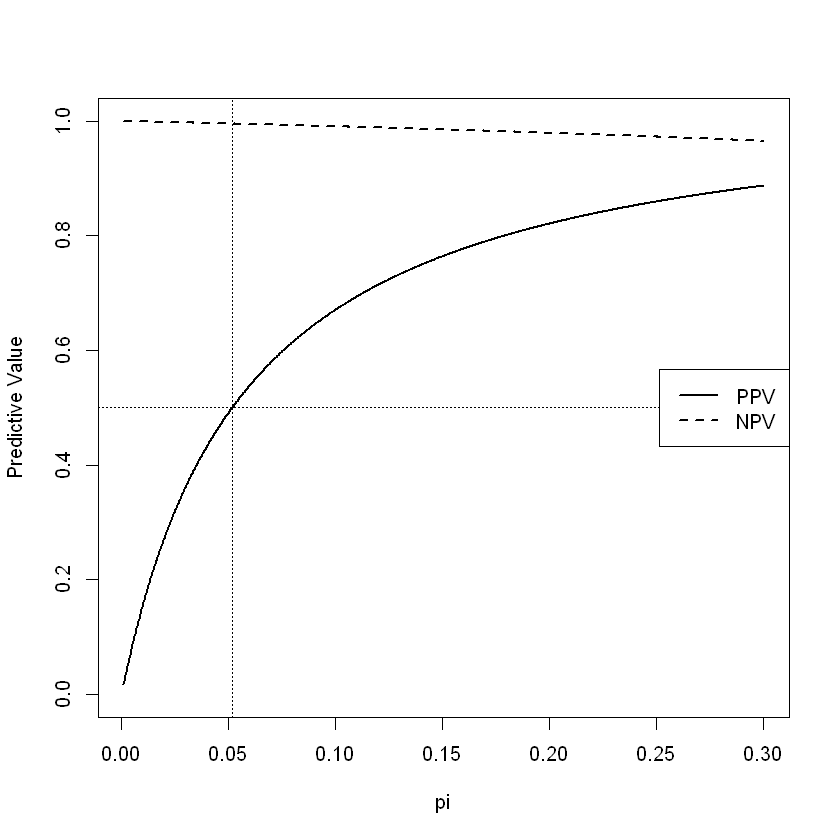

In [14]:
plot(pi_grid, ppv(pi_grid), type = "l", lwd = 2, ylim = c(0, 1), xlab = "pi", ylab = "Predictive Value")
lines(pi_grid, npv(pi_grid), lwd = 2, lty = 2) 
abline(v = pi_cross, lty = 3)
abline(h = 0.5, lty = 3)
legend("right", legend = c("PPV", "NPV"), lty = c(1, 2), lwd = 2)

Crosshairs mark where PPV crosses 50%

## 3)

In [15]:
N <- 1000000
sensitivity <- 0.92
specificity <- 0.95
pi_vec <- c(0.001, 0.01, 0.05, 0.3)
k <- length(pi_vec)
pi_matrix <- matrix(rep(pi_vec, each = N), nrow = N, ncol = k)
# simulate diseased populations
diseased <- matrix(runif(N * k), nrow = N, ncol = k) < pi_matrix
head(pi_matrix, 4)
head(diseased, 8)

0.001,0.01,0.05,0.3
0.001,0.01,0.05,0.3
0.001,0.01,0.05,0.3
0.001,0.01,0.05,0.3


FALSE,FALSE,FALSE,FALSE
FALSE,FALSE,FALSE,FALSE
FALSE,FALSE,FALSE,TRUE
FALSE,FALSE,FALSE,TRUE
FALSE,FALSE,FALSE,TRUE
FALSE,FALSE,TRUE,TRUE
FALSE,FALSE,FALSE,FALSE
FALSE,FALSE,FALSE,TRUE


In [16]:
# simulate testing
p_positive <- ifelse(diseased, sensitivity, 1 - specificity)
positives <- matrix(runif(N * k), nrow = N, ncol = k) < p_positive
negatives <- !positives
head(positives, 8)

FALSE,FALSE,FALSE,FALSE
FALSE,FALSE,FALSE,FALSE
FALSE,TRUE,FALSE,TRUE
FALSE,FALSE,FALSE,TRUE
FALSE,FALSE,FALSE,TRUE
FALSE,FALSE,TRUE,TRUE
FALSE,FALSE,FALSE,FALSE
FALSE,FALSE,FALSE,TRUE


In [17]:
n_positives <- colSums(positives)
n_negatives <- colSums(negatives)
ppv_sim <- colSums(diseased & positives) / n_positives
npv_sim <- colSums(!diseased & negatives) / n_negatives
se_ppv <- sqrt(ppv_sim * (1 - ppv_sim) / n_positives)
se_npv <- sqrt(npv_sim * (1 - npv_sim) / n_negatives)
ppv_bayes <- ppv(pi_vec)
npv_bayes <- npv(pi_vec)

results <- data.frame(pi = pi_vec,
    PPV_Bayes = ppv_bayes, PPV_Sim = ppv_sim, PPV_MC_SE = se_ppv,
    NPV_Bayes = npv_bayes, NPV_Sim = npv_sim, NPV_MC_SE = se_npv)
results

pi,PPV_Bayes,PPV_Sim,PPV_MC_SE,NPV_Bayes,NPV_Sim,NPV_MC_SE
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.001,0.01808532,0.01947272,0.0006131381,0.9999157,0.9999126,9.597482e-06
0.010,0.15672913,0.15517300,0.0014955423,0.9991501,0.9991672,2.973093e-05
0.050,0.49197861,0.49205260,0.0016372638,0.9955874,0.9956857,6.882833e-05
0.300,0.88745981,0.88812654,0.0005646698,0.9651669,0.9650503,2.213502e-04


The simulation estimates are very close to the calculated values for both predictive values. The PPV standard error is small and NPV standard error even smaller. As disease prevalence increases, PPV inscreases becuase becuase a positive test is more likely to be a true positive, while NPV falls because negative results have increasingly false negatives.

---
## Problem 3 — Independence vs pairwise independence (20 pts)

Let fair coin flips \(X_1,X_2\) be independent. Define events  
\(A=\{X_1=H\}\), \(B=\{X_2=H\}\), \(C=\{X_1\oplus X_2=H\}\) (parity).

1. Show analytically that \(A,B,C\) are **pairwise independent** but **not** mutually independent (i.e., \(P(ABC)\neq P(A)P(B)P(C)\)).  
2. Simulate \(10^6\) trials to estimate \(P(A),P(B),P(C),P(AB),P(AC),P(BC),P(ABC)\). Report relative errors vs analytics and discuss convergence.

## 1)

$S=\{(H,H),(H,T),(T,H),(T,T)\}$

$A=\{X_1=H\}=\{(H,H),(H,T)\}$

$B=\{X_2=H\}=\{(H,H),(T,H)\}$

$C=\{X_1\oplus X_2=H\}=\{(H,T),(T,H)\}$

Each outcome has probability $1/4$, so $P(A)=P(B)=P(C)=\frac{2}{4}=\frac{1}{2}$.

$A\cap B=\{(H,H)\}$

$P(A\cap B)=\frac{1}{4}$

$P(A)P(B)=\frac{1}{2}\frac{1}{2}=\frac{1}{4}$

$P(A\cap B)=P(A)P(B)$, so $A$ and $B$ are pairwise independent.

$A\cap C=\{(H,T)\}$

$P(A\cap C)=\frac{1}{4}$

$P(A)P(C)=\frac{1}{2}\frac{1}{2}=\frac{1}{4}$

$P(A\cap C)=P(A)P(C)$, so $A$ and $C$ are pairwise independent.

$B\cap C={(T,H)}$

$P(B\cap C)=\frac{1}{4}$

$P(B)P(C)=\frac{1}{2}\frac{1}{2}=\frac{1}{4}$

$P(B\cap C)=P(B)P(C)$, so $B$ and $C$ are pairwise independent.

For mutual independence, $P(A\cap B\cap C)=P(A)P(B)P(C)$

If both $A$ and $B$ occur, the outcome is $(H,H)$, but $(H,H)$ does not satisfy $C$ since XOR requires exactly one head.

$A\cap B\cap C=\varnothing$ and $P(A\cap B\cap C)=0$

$P(A)P(B)P(C)=\frac{1}{2}\frac{1}{2}\frac{1}{2}=\frac{1}{8}$.

$P(A\cap B\cap C)=0\neq\frac{1}{8}=P(A)P(B)P(C)$.

$A$, $B$, and $C$ are pairwise independent but not mutually independent.

## 2)

In [18]:
N <- 1000000
x1 <- sample(c(0, 1), N, replace = TRUE)
x2 <- sample(c(0, 1), N, replace = TRUE)
A <- (x1 == 1)
B <- (x2 == 1)
C <- xor(A, B)

PA <- mean(A)
PB <- mean(B)
PC <- mean(C)
PAB <- mean(A & B)
PAC <- mean(A & C)
PBC <- mean(B & C)
PABC <- mean(A & B & C)

empirical <- c(A = PA, B = PB, C = PC, AB = PAB, AC = PAC, BC = PBC, ABC = PABC)
empirical

A        B        C       AB       AC       BC      ABC 
0.500015 0.499878 0.500521 0.249686 0.250329 0.250192 0.000000

In [19]:
analytic <- c(A = 1/2, B = 1/2, C = 1/2, AB = 1/4, AC = 1/4, BC = 1/4, ABC = 0)
empirical <- c(A = PA, B = PB, C = PC, AB = PAB, AC = PAC, BC = PBC, ABC = PABC)
rel_error <- abs(empirical - analytic) / analytic
rel_error

A        B        C       AB       AC       BC      ABC 
0.000030 0.000244 0.001042 0.001256 0.001316 0.000768      NaN

As the number of trials increases, the probability estimates converge towards the probabilities calculated in part 1). The relative error is very small for 1,000,000 trials and the simulation agrees with my calculations.

---
## Problem 4 — Monty Hall: conditional reasoning vs simulation (20 pts)

1. Provide a clean derivation showing that, after Monty reveals a goat, **switching wins with probability 2/3** (state assumptions).  
2. Implement a vectorized simulation with \(N=10^6\) comparing **stay** vs **switch** strategies; time the code, report win rates and a 95% CI for the difference.

## 1)

Define the Monty Hall problem:
+ There are 3 doors: one contains a prize and two contain goats
+ Monty knows where the prize is
+ Contestant initially chooses one of the doors
+ After contestant chooses, Monty always opens a door containing a goat
+ The contestant may stay with their initial selection or switch their selection to the unopened door

Let $\text{stay}={\text{stay strategy wins}}$ and $\text{switch}={\text{switch strategy wins}}$.

The probability the initial choice is correct: $P(\text{prize})=\frac{1}{3}$

The probability the initial choice is incorrect: $P(\text{goat})=\frac{2}{3}$

There are two cases:

#### Case 1: Initial choice is correct (prize)

+ In this case, $P(\text{stay}\mid\text{prize})=1$ and $P(\text{switch}\mid\text{prize})=0$.

#### Case 2: Initial choice is incorrect (goat)

+ One of the two remaining doors contains the prize and the other contains the second goat. Monty must open the remaining goat door. The unopened door available for switching must contain the prize, so $P(\text{stay}\mid\text{prize})=0$ and $P(\text{switch}\mid\text{goat})=1$

By law of total probability,

$P(\text{stay})=P(\text{stay}\mid\text{prize})P(\text{prize})+P(\text{stay}\mid\text{goat})P(\text{goat})$

$P(\text{stay})=1\left(\frac{1}{3}\right)+0\left(\frac{2}{3}\right)=\frac{1}{3}$

$P(\text{switch})=P(\text{switch}\mid\text{prize})P(\text{prize})+P(\text{switch}\mid\text{goat})P(\text{goat})$

$=0\left(\frac{1}{3}\right)+1\left(\frac{2}{3}\right)=\frac{2}{3}$

Therefore, $P(\text{stay})=\frac{1}{3}$ and $P(\text{switch})=\frac{2}{3}$

## 2)

In [20]:
N <- 1000000
elapsed <- system.time({
    prize <- sample(1:3, N, replace = TRUE)
    choice <- sample(1:3, N, replace = TRUE)
    stay_win <- (choice == prize)
    switch_win <- !stay_win
})
p_stay <- mean(stay_win)
p_switch <- mean(switch_win)

p_stay
p_switch
elapsed

[1] 0.333318

[1] 0.666682

   user  system elapsed 
   0.07    0.00    0.08 

In [21]:
ci_switch <- binom.test(sum(switch_win), N, conf.level = 0.95)$conf.int
ci_diff <- 2 * ci_switch - 1
ci_diff

[1] 0.3315142 0.3352119
attr(,"conf.level")
[1] 0.95

---
## Problem 5 — Reliability networks under independence (20 pts)

A system has two sub-systems feeding a final series element:

- **Subsystem A:** three components in **parallel** (works if at least one works).  
- **Subsystem B:** two components in **series** (both must work).  
- **Final stage:** series with A and B and a final component.  

Let component reliabilities be independent \(p_1,\dots,p_6\).

1. Derive a closed-form expression \(R(p_1,\dots,p_6)\) for the system reliability.  
2. Validate with Monte Carlo for randomly drawn reliabilities in \([0.7,0.99]\) using \(N=10^6\); report MC error.  
3. Compute numerical sensitivities \(\partial R/\partial p_i\) (finite differences); identify the component with greatest leverage and interpret.

## 1)

Let $E_i=\{\text{component }i\text{ works}\}$, where $P(E_i)=p_i$, for $i=1,\dots,6$ and all components are independent.

Subsystem A contains components $1$, $2$, and $3$ in parallel: $A=E_1\cup E_2\cup E_3$

Subsystem A fails only if all three components fail: $P(A^c)=(1-p_1)(1-p_2)(1-p_3)$

$P(A)=1-(1-p_1)(1-p_2)(1-p_3)$.

Subsystem B contains components $4$ and $5$ in series: $B=E_4\cap E_5$

Becuase they are independent, $P(B)=p_4p_5$

For the final stage, Subsystem A, Subsystem B, and component $6$ are all in series. Let $S$ denote the event that the system works: $S=A\cap B\cap E_6$.

Because they are independent, $P(S)=P(A)P(B)P(E_6)$

and system reliability is: $R(p_1,\dots,p_6)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right](p_4p_5)(p_6)$

## 2)

In [22]:
reliability <- function(p) {
    rel_A <- 1 - (1 - p[1]) * (1 - p[2]) * (1 - p[3])
    rel_B <- p[4] * p[5]
    return(rel_A * rel_B * p[6])
}

In [23]:
N <- 1000000
p <- runif(6, min = 0.7, max = 0.99)
c1 <- rbinom(N, 1, p[1])
c2 <- rbinom(N, 1, p[2])
c3 <- rbinom(N, 1, p[3])
c4 <- rbinom(N, 1, p[4])
c5 <- rbinom(N, 1, p[5])
c6 <- rbinom(N, 1, p[6])

A <- (c1 == 1) | (c2 == 1) | (c3 == 1)
B <- (c4 == 1) & (c5 == 1)
system <- A & B & (c6 == 1)

R_sim <- mean(system)
std_err <- sqrt(R_sim * (1 - R_sim) / N)
R_exact <- reliability(p)

p
R_exact
R_sim
std_err

[1] 0.7845477 0.8939789 0.7773481 0.8400949 0.9381582 0.9107218

[1] 0.7141275

[1] 0.714748

[1] 0.0004515344

## 3)

$R(p_1,\dots,p_6)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6$

We can let the system represent a circuit. The leverage of component $i$ is the partial derivative $\dfrac{\partial R}{\partial p_i}$

#### Component $i=1$:

$$\dfrac{\partial R}{\partial p_1}=\dfrac{\partial}{\partial p_1}\left(\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6\right)=p_4p_5p_6\dfrac{\partial}{\partial p_1}\left[1-(1-p_1)(1-p_2)(1-p_3)\right]$$

$$=p_4p_5p_6\left[-(1-p_2)(1-p_3)\dfrac{\partial}{\partial p_1}(1-p_1)\right]=p_4p_5p_6\left[(1-p_2)(1-p_3)\right]=(1-p_2)(1-p_3)p_4p_5p_6$$

#### Component $i=2$:

$$\dfrac{\partial R}{\partial p_2}=\dfrac{\partial}{\partial p_2}\left(\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6\right)=p_4p_5p_6\dfrac{\partial}{\partial p_2}\left[1-(1-p_1)(1-p_2)(1-p_3)\right]$$

$$=p_4p_5p_6\left[-(1-p_1)(1-p_3)\dfrac{\partial}{\partial p_2}(1-p_2)\right]=p_4p_5p_6\left[(1-p_1)(1-p_3)\right]=(1-p_1)(1-p_3)p_4p_5p_6$$

#### Component $i=3$:

$$\dfrac{\partial R}{\partial p_3}=\dfrac{\partial}{\partial p_3}\left(\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6\right)=p_4p_5p_6\dfrac{\partial}{\partial p_3}\left[1-(1-p_1)(1-p_2)(1-p_3)\right]$$

$$=p_4p_5p_6\left[-(1-p_1)(1-p_2)\dfrac{\partial}{\partial p_3}(1-p_3)\right]=p_4p_5p_6\left[(1-p_1)(1-p_2)\right]=(1-p_1)(1-p_2)p_4p_5p_6$$

#### Component $i=4$:

$$\dfrac{\partial R}{\partial p_4}=\dfrac{\partial}{\partial p_4}\left(\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6\right)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]\dfrac{\partial}{\partial p_4}(p_4p_5p_6)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_5p_6\dfrac{\partial}{\partial p_4}p_4$$

$$=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_5p_6$$

#### Component $i=5$:

$$\dfrac{\partial R}{\partial p_5}=\dfrac{\partial}{\partial p_5}\left(\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6\right)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]\dfrac{\partial}{\partial p_5}(p_4p_5p_6)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_6\dfrac{\partial}{\partial p_5}p_5$$

$$=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_6$$

#### Component $i=6$:

$$\dfrac{\partial R}{\partial p_6}=\dfrac{\partial}{\partial p_6}\left(\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5p_6\right)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]\dfrac{\partial}{\partial p_6}(p_4p_5p_6)=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5\dfrac{\partial}{\partial p_6}p_6$$

$$=\left[1-(1-p_1)(1-p_2)(1-p_3)\right]p_4p_5$$

In [24]:
R <- function(p1, p2, p3, p4, p5, p6) {
  (1 - (1-p1)*(1-p2)*(1-p3))*p4*p5*p6
}

leverage <- function(p1, p2, p3, p4, p5, p6) {
    dR_dp1 <- (1-p2)*(1-p3)*p4*p5*p6
    dR_dp2 <- (1-p1)*(1-p3)*p4*p5*p6
    dR_dp3 <- (1-p1)*(1-p2)*p4*p5*p6
    dR_dp4 <- (1-(1-p1)*(1-p2)*(1-p3))*p5*p6
    dR_dp5 <- (1-(1-p1)*(1-p2)*(1-p3))*p4*p6
    dR_dp6 <- (1-(1-p1)*(1-p2)*(1-p3))*p4*p5
    return(c(dR_dp1, dR_dp2, dR_dp3, dR_dp4, dR_dp5, dR_dp6))
}

p_values <- c(0, 0.5, 1)
for (p in p_values) {
    cat("\np =", p, "\n")
    cat("System reliability =", R(p, p, p, p, p, p), "\n")
    print(leverage(p, p, p, p, p, p))
}


p = 0 
System reliability = 0 
[1] 0 0 0 0 0 0

p = 0.5 
System reliability = 0.109375 
[1] 0.03125 0.03125 0.03125 0.21875 0.21875 0.21875

p = 1 
System reliability = 1 
[1] 0 0 0 1 1 1


In [25]:
0.21875 / 0.03125

[1] 7

Components 4, 5, and 6 have the greatest leverage because they are in series and are a single point of failure, while components 1, 2, and 3 are in parallel so they have redundancy. When $p=0.5$, increasing $p_4$, $p_5$, or $p_6$ has 7 times the effect on system reliability as increasing $p_1$, $p_2$, $p_3$.

---
## Problem 6 — Conditional chains & the multiplication rule (EC)

A router sees three slots. In any slot, packet size is **Large (L)** with prob 0.3 and **Small (S)** with prob 0.7. If the **previous** packet was Large, the next packet is dropped with prob 0.1; otherwise with prob 0.02. Within a slot, size and drop are independent, but the drop depends on previous size.

1. Using conditional chaining (or a probability tree), compute analytically \(P(\text{no drops in 3 slots})\).  
2. Simulate \(10^6\) sequences and compare to the analytic result.

---
## Problem 7 — Waiting times: geometric distribution (EC)

Let \(T\) be the trial index of the first success in i.i.d. Bernoulli(\(p\)).

1. Derive \(P(T=k)=(1-p)^{k-1}p\).  
2. Show \(E[T]=1/p\) and \(\operatorname{Var}(T)=(1-p)/p^2\) by summation (no mgf).  
3. For \(p\in\{0.2,0.5,0.8\}\), simulate \(10^6\) samples to estimate mean/variance and report relative errors. Include one log-scale histogram overlaid with the theoretical pmf.

---
## Problem 8 — Bayes with a partition: toy Naïve Bayes spam filter (EC)

Tokens: **offer (O)**, **free (F)**, **meeting (M)**. Prior \(P(S)=0.6\).  
Conditional on **spam** (S): \(P(O|S)=0.5, P(F|S)=0.6, P(M|S)=0.1\) independently.  
Conditional on **ham** (H): \(P(O|H)=0.05, P(F|H)=0.1, P(M|H)=0.4\) independently.

1. For an email with O and F but not M, compute \(P(S\mid O,F,M^c)\) by Bayes’ rule using the \(\{S,H\}\) partition and conditional independence. Show steps.  
2. Write `posterior_spam(obs_vec)` to handle any combination of the three tokens (Bernoulli features); return the posterior and the Bayes-optimal decision.  
3. Evaluate all \(2^3\) token patterns; tabulate likelihoods, posteriors, and decisions; briefly discuss how priors and token reliabilities affect results.

---
## Implementation & Style Requirements (graded across problems)

- **Reproducibility (3 pts):** fixed seed; no manual inputs; runs cleanly on “Restart & Run All”.  
- **Numerical care (3 pts):** stable probabilities; vectorize where sensible.  
- **Validation (3 pts):** test derived formulas via enumeration or simulation.  
- **Clarity (3 pts):** each problem begins with a plan/derivation, followed by code and interpretation.

---
## Submission Checklist

- File named `lastname_firstname_ch3_conditional_independence.ipynb`  
- Kernel: **R**  
- All plots inline; random processes seeded  
- Runtime ≤ ~2 minutes (reduce N if needed, but keep ≥ \(10^5\) for major simulations)